# EDA Walkthrough - Ethereum Address Classification Project

This notebook consolidates the exploratory data analysis (EDA) process that
otherwise lives split across `eda.py` and `visualize_graph_topology.py`, so
each step of code sits directly next to the figure/table it produces.

**Data source**: the nonseed-to-nonseed augmented reconstructed graph (`raw_edges_reconstructed.csv`,
`seed_feature_matrix_reconstructed.csv`) - this is the main-line dataset
used by the dissertation experiments. The
counterparty-to-counterparty edges missing from the original Top-100-per-seed
sampling have been filled in via BigQuery, while every seed-level
transaction-behaviour feature is verified numerically identical to the
original sampled graph.

Sections:
1. Activity by label
2. Skewness: raw vs. log1p
3. Zero-inflation by label
4. Feature distributions by label
5. Feature correlation heatmap
6. Graph topology visualisation (ego-networks)


## 0. Setup

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "00_data_graph").is_dir():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the dissertation workspace")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
LABEL_COL = "label"
LABEL_ORDER = ["CEX", "DeFi", "Malicious_MEV"]
LABEL_COLORS = {"CEX": "#2a78d6", "DeFi": "#1baf7a", "Malicious_MEV": "#e34948"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "grid.color": "#e1e0d9",
    "font.size": 10,
})


def clean_address(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip().lower()


feat = pd.read_csv(PROJECT_ROOT / "02_feature_engineering" / "feature_engineering" / "seed_feature_matrix_reconstructed.csv")
print(f"Loaded feature matrix: {feat.shape[0]} rows, {feat.shape[1]} columns")

assert feat["out_gas_fee_mean"].isna().sum() == 0, "run feature_engineering.py first"
assert feat["in_gas_fee_mean"].isna().sum() == 0, "run feature_engineering.py first"


Loaded feature matrix: 500 rows, 42 columns


## 1. Activity by label

DeFi seeds have a substantially lower active rate than CEX/Malicious_MEV —
inactive seeds have no recorded transactions in the 90-day sampling window at
all (all-zero transaction/graph features), so they are excluded from every
downstream distribution/skew/correlation analysis below.


In [2]:
activity = feat.groupby(LABEL_COL)["is_active"].agg(
    active="sum", total="count", active_rate="mean"
).reindex(LABEL_ORDER)
activity["active_rate"] = activity["active_rate"].round(4)
activity


,active,total,active_rate
label,,,
CEX,51,51,1.0000
DeFi,86,150,0.5733
Malicious_MEV,299,299,1.0000


In [3]:
active = feat[feat["is_active"]].copy()
print(f"Active subset used for distribution/skew/correlation analysis: "
      f"{len(active)} of {len(feat)} seeds "
      "(inactive seeds have all-zero transaction/graph features and would flatten the plots).")


Active subset used for distribution/skew/correlation analysis: 436 of 500 seeds (inactive seeds have all-zero transaction/graph features and would flatten the plots).


## 2. Skewness: raw vs. log1p

`total_tx_count`/`total_eth_value`/`degree`/`weighted_degree` all become far
less skewed after a log1p transform. `pagerank` is the exception — its raw
values already sit close to zero (mean ≈ 1/8029 nodes), where log1p(x) ≈ x,
so log1p barely reduces its skew. This is why pagerank is instead handled
with a percentile-rank transform downstream in the classification pipeline
rather than log1p.


In [4]:
skew_pairs = [
    ("total_tx_count", "log_total_tx_count"),
    ("total_eth_value", "log_total_eth_value"),
    ("degree", "log_degree"),
    ("weighted_degree", "log_weighted_degree"),
    ("pagerank", "log_pagerank"),
]

skew_rows = []
for raw_col, log_col in skew_pairs:
    skew_rows.append({
        "feature": raw_col,
        "raw_skew": active[raw_col].skew(),
        "log_skew": active[log_col].skew(),
    })
skew_df = pd.DataFrame(skew_rows).round(3)
skew_df


,feature,raw_skew,log_skew
0,total_tx_count,12.269,-0.784
1,total_eth_value,14.613,2.302
2,degree,1.142,0.460
3,weighted_degree,12.269,-0.784
4,pagerank,6.388,6.373


## 3. Zero-inflation by label

`clustering_coeff` and `weighted_degree` are computed on the **full 500-seed
set** (including inactive seeds, which are trivially zero everywhere) to show
the true scale of zero-inflation across the whole dataset, not just the
active subset.


In [5]:
zero_cols = ["total_tx_count", "total_eth_value", "out_edge_count", "in_edge_count",
             "clustering_coeff", "weighted_degree"]

zero_rows = []
for label in LABEL_ORDER:
    sub = feat[feat[LABEL_COL] == label]
    row = {"label": label, "n": len(sub)}
    for col in zero_cols:
        row[f"pct_zero_{col}"] = round((sub[col] == 0).mean(), 4)
    zero_rows.append(row)
zero_df = pd.DataFrame(zero_rows)
zero_df


,label,n,pct_zero_total_tx_count,pct_zero_total_eth_value,pct_zero_out_edge_count,pct_zero_in_edge_count,pct_zero_clustering_coeff,pct_zero_weighted_degree
0,CEX,51,0.0000,0.0588,0.0980,0.6078,0.7843,0.0000
1,DeFi,150,0.4267,0.8200,1.0000,0.4267,0.9200,0.4267
2,Malicious_MEV,299,0.0000,0.1304,0.0268,0.1940,0.3980,0.0000


## 4. Feature distributions by label

Box plots of the (mostly log-transformed) engineered features, split by
address class, active seeds only.


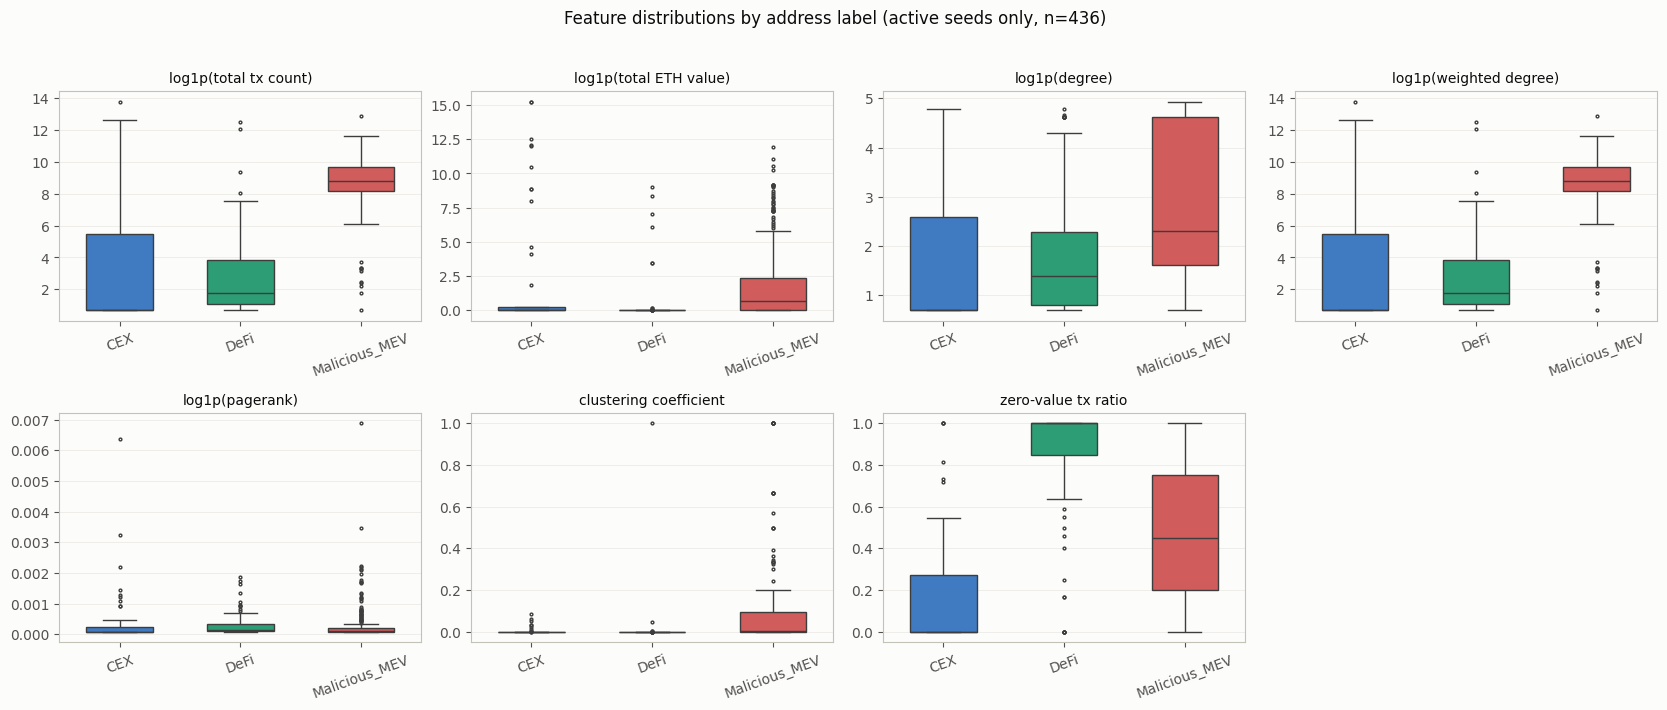

In [6]:
plot_cols = [
    ("log_total_tx_count", "log1p(total tx count)"),
    ("log_total_eth_value", "log1p(total ETH value)"),
    ("log_degree", "log1p(degree)"),
    ("log_weighted_degree", "log1p(weighted degree)"),
    ("log_pagerank", "log1p(pagerank)"),
    ("clustering_coeff", "clustering coefficient"),
    ("zero_value_tx_ratio", "zero-value tx ratio"),
]

n_cols = 4
n_rows = int(np.ceil(len(plot_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.6 * n_rows))
axes = axes.flatten()

for ax, (col, title) in zip(axes, plot_cols):
    sns.boxplot(
        data=active, x=LABEL_COL, y=col, order=LABEL_ORDER,
        hue=LABEL_COL, palette=LABEL_COLORS, legend=False,
        width=0.55, linewidth=1, fliersize=2, ax=ax,
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", linewidth=0.6, alpha=0.6)
    ax.set_axisbelow(True)

for ax in axes[len(plot_cols):]:
    ax.axis("off")

fig.suptitle("Feature distributions by address label (active seeds only, n=%d)" % len(active), fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


## 5. Feature correlation heatmap

`log_total_tx_count` and `log_weighted_degree` are perfectly correlated
(r = 1.00) — edge weight *is* tx_count and there are no duplicate
source-target rows, so weighted-degree is mechanically identical to tx_count.
This is why the weighted-degree columns are assigned to the
`transaction_behaviour` feature group rather than `graph_structural` (see
`feature_groups.json` / `feature_engineering.py`).


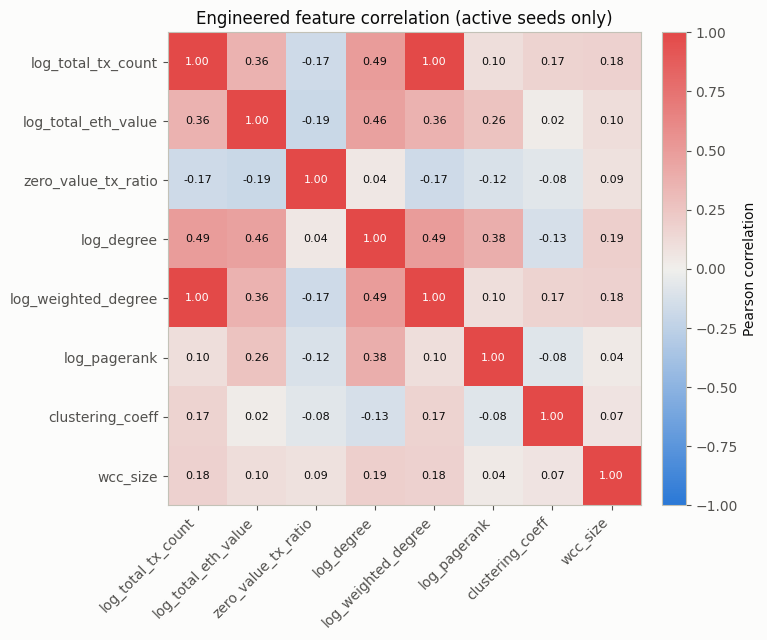

In [7]:
corr_cols = [
    "log_total_tx_count", "log_total_eth_value", "zero_value_tx_ratio",
    "log_degree", "log_weighted_degree", "log_pagerank", "clustering_coeff", "wcc_size",
]
corr = active[corr_cols].corr()

diverging_cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"]
)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap=diverging_cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr.iloc[i, j]
        text_color = "#ffffff" if abs(val) > 0.6 else "#0b0b0b"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8, color=text_color)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pearson correlation")
ax.set_title("Engineered feature correlation (active seeds only)", fontsize=12)
fig.tight_layout()
plt.show()


## 6. Graph topology visualisation (ego-networks)

§3.3 quantified the graph's connectivity (zero-inflated clustering
coefficients); this section shows it directly. Four example seeds (a
high-degree DeFi hub, a high-degree CEX hub, a high-degree Malicious_MEV hub,
and a typical/median-degree Malicious_MEV seed) with their direct neighbours
(blue) and the seed itself (red). The subtitle reports how many edges exist
*among the neighbours themselves* — this is exactly what `clustering_coeff`
measures.


In [8]:
edges = pd.read_csv(PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv")
edges["source"] = edges["source"].apply(clean_address)
edges["target"] = edges["target"].apply(clean_address)
edges = edges.dropna(subset=["source", "target"])

G = nx.from_pandas_edgelist(edges, source="source", target="target", create_using=nx.DiGraph())
G_undirected = G.to_undirected()
print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

seeds_df = pd.read_csv(PROJECT_ROOT / "00_data_graph" / "data" / "main" / "final_seed_address500.csv")
seeds_df["address"] = seeds_df["address"].apply(clean_address)
label_of = seeds_df.set_index("address")["label"].to_dict()

EXAMPLE_SEEDS = [
    "0x111111125421ca6dc452d289314280a0f8842a65",  # DeFi, high-degree hub
    "0x28c6c06298d514db089934071355e5743bf21d60",  # CEX, high-degree hub
    "0x331d9a049d496385998067abf6cbb6371c8d2466",  # Malicious_MEV, high-degree hub
    "0x5ae028a6478ca2d3b881c51440674ff9af21341f",  # Malicious_MEV, typical/median degree
]


Graph: 8029 nodes, 47197 edges


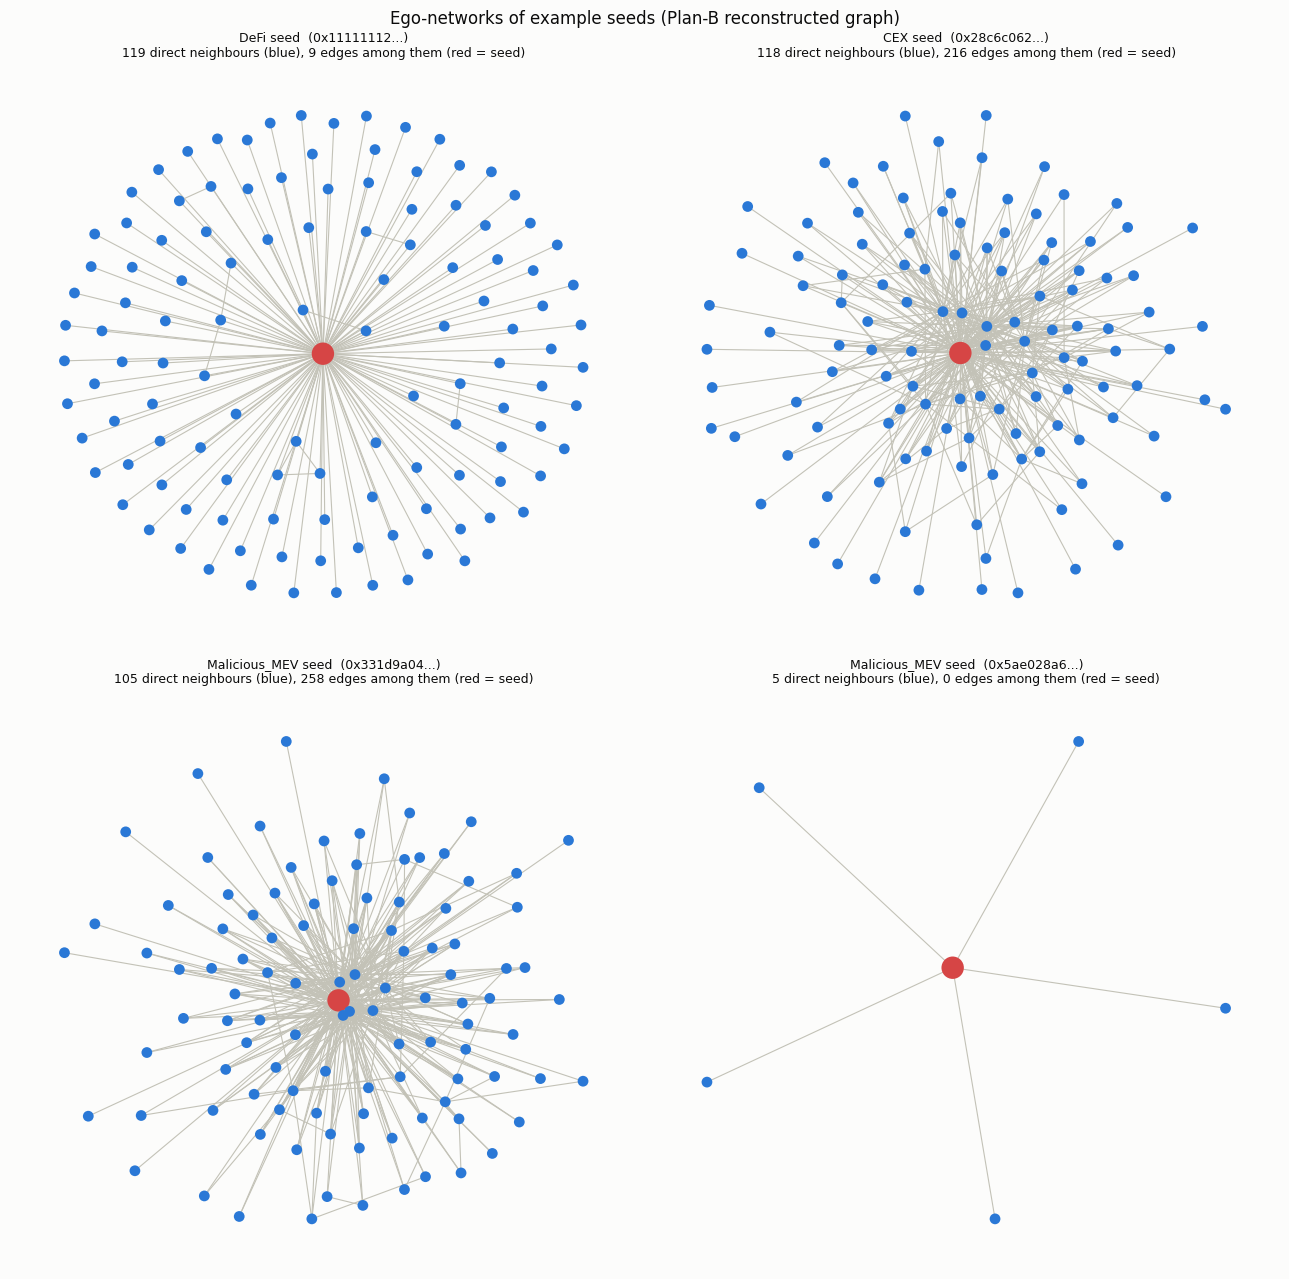

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 13))

for ax, seed in zip(axes.flat, EXAMPLE_SEEDS):
    ego = nx.ego_graph(G_undirected, seed, radius=1)
    n_neighbours = ego.number_of_nodes() - 1
    neighbour_subgraph = ego.subgraph([n for n in ego.nodes() if n != seed])
    n_neighbour_edges = neighbour_subgraph.number_of_edges()

    pos = nx.spring_layout(ego, seed=42, k=0.6)
    node_colors = ["#d64545" if n == seed else "#2a78d6" for n in ego.nodes()]
    node_sizes = [260 if n == seed else 60 for n in ego.nodes()]

    nx.draw_networkx_edges(ego, pos, ax=ax, edge_color="#c3c2b7", width=0.8)
    nx.draw_networkx_nodes(ego, pos, ax=ax, node_color=node_colors, node_size=node_sizes, linewidths=0)

    label = label_of.get(seed, "?")
    ax.set_title(
        f"{label} seed  ({seed[:10]}...)\n"
        f"{n_neighbours} direct neighbours (blue), {n_neighbour_edges} edges among them (red = seed)",
        fontsize=9,
    )
    ax.axis("off")

fig.suptitle("Ego-networks of example seeds (nonseed-to-nonseed augmented graph)", fontsize=12)
fig.tight_layout()
plt.show()


The combined view below overlays all four seeds' ego-networks in one layout,
so how they tile together (separately, or overlapping into shared
communities) is visible directly.


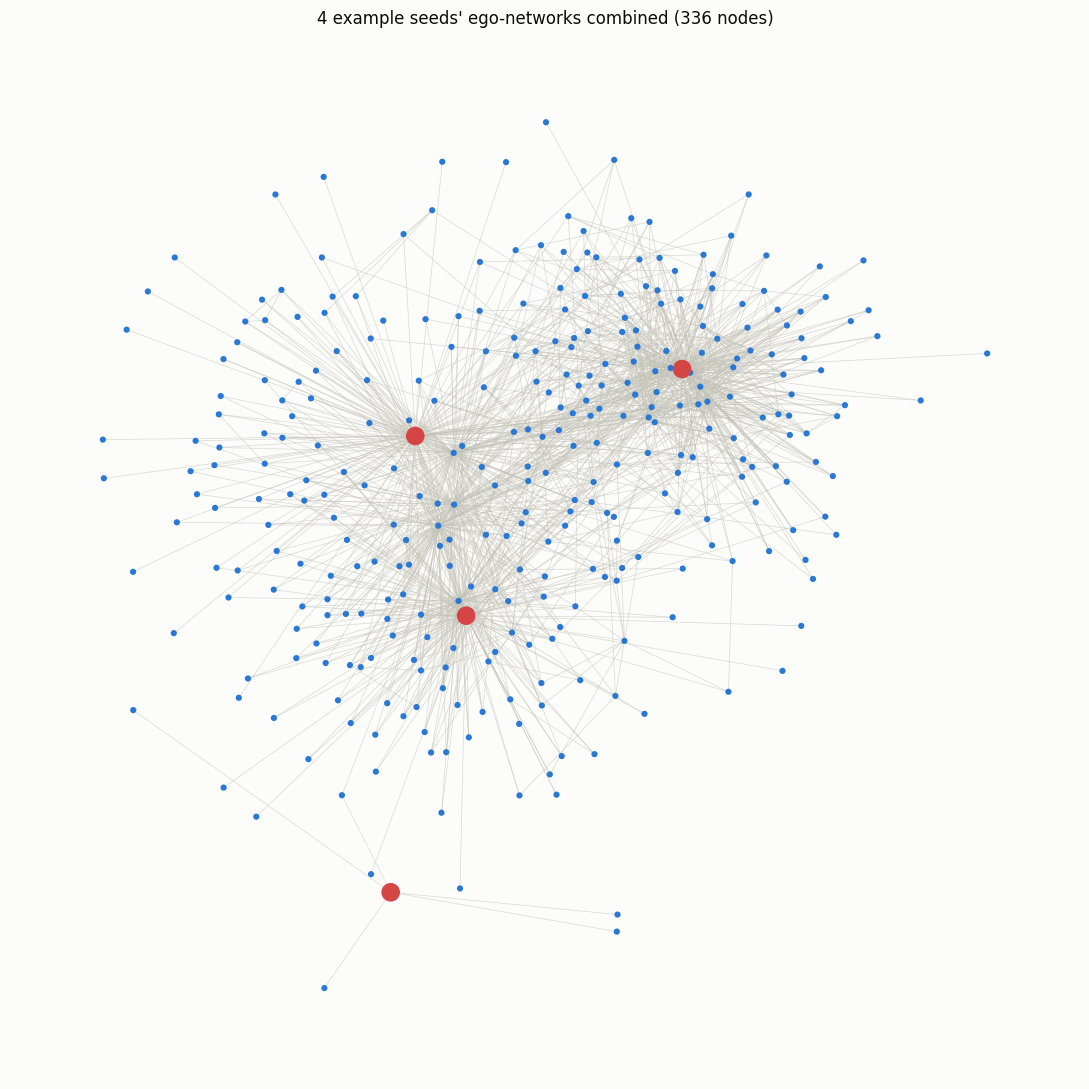

In [10]:
sample_nodes = set()
for seed in EXAMPLE_SEEDS:
    sample_nodes.update(nx.ego_graph(G_undirected, seed, radius=1).nodes())
sample_graph = G_undirected.subgraph(sample_nodes)

fig2, ax2 = plt.subplots(figsize=(11, 11))
pos2 = nx.spring_layout(sample_graph, seed=42, k=0.25, iterations=50)
node_colors2 = ["#d64545" if n in EXAMPLE_SEEDS else "#2a78d6" for n in sample_graph.nodes()]
node_sizes2 = [180 if n in EXAMPLE_SEEDS else 20 for n in sample_graph.nodes()]
nx.draw_networkx_edges(sample_graph, pos2, ax=ax2, edge_color="#c3c2b7", width=0.5, alpha=0.6)
nx.draw_networkx_nodes(sample_graph, pos2, ax=ax2, node_color=node_colors2, node_size=node_sizes2, linewidths=0)
ax2.set_title(f"4 example seeds' ego-networks combined ({sample_graph.number_of_nodes()} nodes)")
ax2.axis("off")
fig2.tight_layout()
plt.show()
